<a href="https://colab.research.google.com/github/T1toh/30Days_of_SQL/blob/main/MODULE_5_%7C_LESSON_4_Mean_Reversion_Applications.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CAPSTONE REVIEW**
## MODULE 5 | LESSON 4: Mean-Reversion Applications

| | |
|:---|:---|
|**Reading Time** | 5h |
|**Prior Knowledge** | Time series analysis, stochastic processes, basic econometrics, option pricing theory, portfolio optimization |
|**Keywords** | mean reversion, Ornstein-Uhlenbeck process, pairs trading, cointegration, statistical arbitrage, principal component analysis, Kalman filtering, regime switching models, change-point detection |

---

## **Introduction**

Mean reversion is like gravity in financial markets – an invisible force that eventually pulls prices back to earth. But here's the rub: unlike gravity, which works predictably, mean reversion in markets is fickle, sometimes strong, sometimes absent entirely.

A bit more precisely, mean reversion describes the tendency of financial variables to return to their long-term average levels after deviating from them. This phenomenon creates what many consider the holy grail of trading: systematic opportunities to profit from predictable price movements. Yet the efficient market hypothesis tells us such opportunities shouldn't exist (why?). The resolution to this paradox lies in understanding when, where, and how mean reversion manifests – and when it spectacularly fails.

It pays to examine why mean reversion occurs at all. In some markets, physical constraints create natural boundaries – oil can't stay at $200 forever because demand destruction kicks in. In others, economic relationships anchor prices together. But here's what makes this fascinating: mean reversion isn't always there. Sometimes relationships that held for decades suddenly break, leaving traders who bet on their persistence nursing spectacular losses.

Note that we'll approach mean reversion from multiple angles in this lesson. We start with pairs trading – the bread and butter of statistical arbitrage desks. We then advance to more sophisticated techniques using principal components (think of it as pairs trading on steroids). Volatility markets get special treatment because, surprisingly, they exhibit stronger mean reversion than price markets. Our journey continues through relative value strategies, computational methods for tracking time-varying parameters, and – crucially – techniques for detecting when mean reversion breaks down.

## **1. Pairs Trading Implementation Using Cointegration**

Pairs trading is the gateway drug of quantitative finance – simple enough to understand, sophisticated enough to make money, and dangerous enough to blow up spectacularly when misapplied. At its core lies a beautifully simple idea: find two things that move together and bet on their reunion when they drift apart.

### **1.1 Theoretical Foundation**

Consider two oil companies, say Exxon and Shell. Their stock prices dance to similar tunes – oil prices, refining margins, global demand. Yet sometimes one zigs while the other zags. A pairs trader asks: is this divergence temporary noise or a fundamental shift? The mathematics of cointegration provides the answer.

Here's the key insight: individual stock prices are like drunken sailors, wandering randomly with no particular destination. But the distance between two particular sailors might stay remarkably constant – they're stumbling together. Mathematically, we express this relationship as:

$$S_t = P_A(t) - \beta P_B(t) - \alpha$$

The spread $S_t$ represents the "distance" between our two stocks after adjusting for their typical relationship. If this spread is stationary (unlike the individual prices), we've found cointegration. The parameter $\beta$ tells us how many shares of stock B to short for each share of stock A we buy.

It pays to understand what cointegration really means. Correlation measures co-movement in returns – useful but insufficient. Two stocks can be highly correlated yet drift apart forever (why?). Cointegration is stronger: it says there's an elastic band connecting the prices. They can stretch apart, but economic forces pull them back together.

### **1.2 Implementation Framework**

Finding cointegrated pairs is like panning for gold – you sift through mountains of data hoping for a few nuggets. The process starts with the universe selection. Most practitioners begin with economic intuition: companies in the same industry, exposed to similar factors. But beware – sometimes the best pairs come from unexpected places.

The Engle-Granger procedure gives us a systematic approach. First, we run a regression: $P_A(t) = \alpha + \beta P_B(t) + \epsilon_t$. This looks deceptively simple (doesn't it?). The residuals $\hat{\epsilon}_t$ from this regression represent our potential trading signal. But here's the critical test: are these residuals stationary? We apply the augmented Dickey-Fuller test, looking for evidence that deviations don't persist forever.

Once we've confirmed cointegration, we model the spread dynamics. The Ornstein-Uhlenbeck process captures the essence of mean reversion:

$$dS_t = \kappa(\mu - S_t)dt + \sigma dW_t$$

Three parameters govern our trading universe. The mean-reversion speed $\kappa$ tells us how quickly profits arrive – higher is better, but suspiciously high values often signal overfitting. The long-term mean $\mu$ anchors our expectations. The volatility $\sigma$ determines position sizing and risk.

Note that estimation isn't straightforward. Maximum likelihood methods work, but they assume parameters stay constant – a heroic assumption in financial markets. More sophisticated approaches use rolling windows or particle filters. The half-life of mean reversion, roughly $0.69/\kappa$, provides intuition: if the half-life exceeds your investment horizon, find another trade.

### **1.3 Trading Rules and Risk Management**

The mechanics of trading resemble a coiled spring. We wait for the spread to stretch beyond normal bounds, then position ourselves to profit from the snapback. The z-score provides our trigger:

$$z_t = \frac{S_t - \bar{S}}{\sigma_S}$$

Entry rules vary, but typical thresholds are 2 standard deviations for entry, 0.5 for exit. This asymmetry is deliberate – we demand significant divergence before risking capital but take profits quickly. Some traders add time-based stops (if convergence hasn't occurred within the expected half-life, something's wrong).

Position sizing requires careful calibration. The hedge ratio $\beta$ ensures market neutrality, but we still need to determine overall exposure. Kelly criterion provides theoretical guidance, but practitioners typically use fractional Kelly (why?). A position consuming 5-10% of capital represents a reasonable balance between diversification and meaningful returns.

Here's where theory meets reality: cointegration relationships break. Companies merge, technologies disrupt, regulations change. Risk management isn't optional – it's survival. Stop losses at 3-4 standard deviations prevent catastrophic losses, though they guarantee you'll exit precisely when mean reversion is most likely (the paradox of stops). More sophisticated approaches monitor the stability of the cointegration relationship itself, reducing positions when evidence of breakdown emerges.

**Pairs Trading Walk‑Through**

Our goal is to reproduce the classic Engle–Granger cointegration test and a simple mean‑reversion strategy on two oil majors  
**Exxon (XOM)** and **CVX (CVX)**, using nothing more than public `yfinance` data.


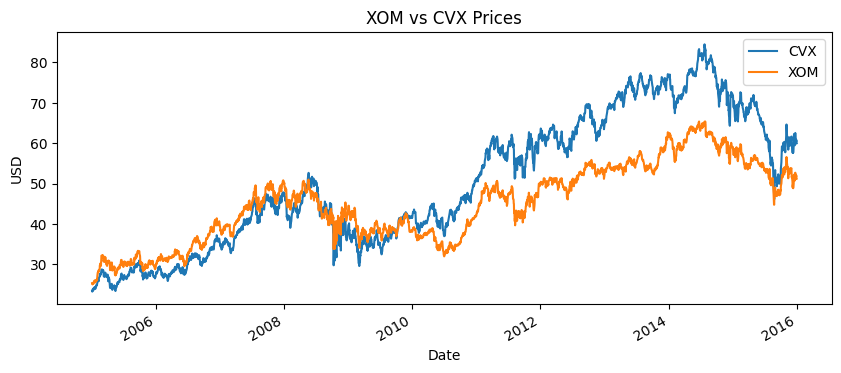

In [2]:
# Imports
import yfinance as yf
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt

# Download data
"""
tickers = ["XOM", "CVX"]
prices = yf.download(tickers, start="2005-01-01", end="2016-01-01", progress=False)["Close"]
prices = prices.dropna()          # keep only dates where we have both stocks
"""

prices = pd.read_csv("/content/prices.csv", index_col = "Date", parse_dates = True)

prices.plot(figsize=(10,4), title="XOM vs CVX Prices")
plt.ylabel("USD")
plt.show()

**Estimate the hedge ratio $\beta$ by OLS**

We regress $P_\text{XOM} = \alpha + \beta P_\text{CVX} + \epsilon_t$ and keep the residuals as the *spread*.


In [3]:
# OLS regression and spread
y = prices["XOM"]
X = sm.add_constant(prices["CVX"])
model = sm.OLS(y, X).fit()
alpha, beta = model.params
spread = y - (alpha + beta * prices["CVX"])
spread.name = "Spread"
beta

0.553516764659841

**Check if the spread is stationary**  

We use the Augmented Dickey–Fuller test; the null hypothesis is *unit root* (non‑stationary).  
A p‑value below 0.05 gives us statistical comfort.


In [4]:
# ADF test
adf_stat, pvalue, *_ = adfuller(spread)
print(f"ADF statistic = {adf_stat:.3f},   p‑value = {pvalue:.4f}")


ADF statistic = -3.009,   p‑value = 0.0341


/tmp/ipykernel_2378/4027885998.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, pvalue, *_ = adfuller(spread)


**Compute z‑scores and trading signals**

We set entry thresholds at $ \pm 2 \sigma$ and exit at $ \pm 0.5 \sigma$.  
Long spread -> buy XOM, short $\beta$ shares of CVX.  
Short spread -> reverse the position.


In [5]:
# Signals
zscore = (spread - spread.rolling(252).mean()) / spread.rolling(252).std()
long_entry  = zscore <= -2
short_entry = zscore >=  2
exit        = zscore.abs() < 0.5

position = np.where(long_entry,  1,
           np.where(short_entry, -1, np.nan))
position = pd.Series(position, index=prices.index).ffill().where(~exit, 0)
position.name = "Spread Position"
position.tail()



,Spread Position
Date,
2015-12-24,-1.0
2015-12-28,0.0
2015-12-29,0.0
2015-12-30,-1.0
2015-12-31,-1.0


**Back‑test (gross of costs)**

Daily P&L comes from the *delta* of the spread times the position held the previous day.


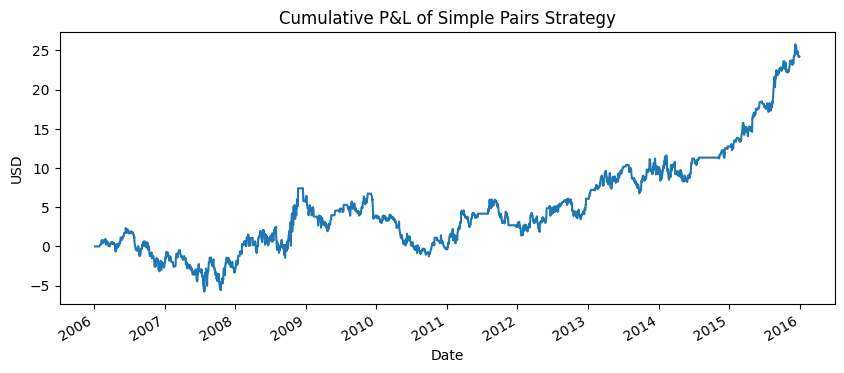

Annualised Sharpe ≈ 0.45


In [6]:
# Strategy returns
spread_returns = spread.diff()
strategy_ret   = position.shift() * spread_returns
cum_pnl = strategy_ret.cumsum()

# Results
fig, ax = plt.subplots(figsize=(10,4))
cum_pnl.plot(ax=ax, title="Cumulative P&L of Simple Pairs Strategy")
ax.set_ylabel("USD")
plt.show()

annual_sharpe = (strategy_ret.mean() / strategy_ret.std()) * np.sqrt(252)
print(f"Annualised Sharpe ≈ {annual_sharpe:.2f}")



The regression gives a *static hedge ratio* of $\beta \approx 0.55$, so one dollar of CVX is offset with roughly fifty‑five cents of XOM.  
The Augmented‑Dickey–Fuller test on the residual spread produces a statistic of $-3.01$ and a $p$‑value of $0.034$, allowing rejection of the unit‑root null at the $5\%$ level; hence the two price series are **cointegrated** in the Engle–Granger sense, and the estimated spread is mean‑reverting with a long‑run equilibrium of $\alpha \approx 0.38\ \text{USD}$.  

Exploiting this, the simple threshold‑based pairs strategy—entering when the $252$‑day $z$‑score breaches $\pm 2$ and exiting once it reverts inside $\pm 0.5$—generates a cumulative profit of about $25\ \text{USD}$ per share pair over the $2005$–$2016$ window and an annualised Sharpe ratio of $\approx 0.45$.  

Although the equity curve trends upward after the $2008$–$09$ dislocation and again post‑$2012$, a Sharpe below unity signals only *modest* risk‑adjusted performance; furthermore, these results ignore financing, bid–ask, and execution costs, and they rely on a **constant** hedge ratio instead of a time‑varying $\beta$. In practice one would test robustness to rolling‑window $\beta$ estimation, alternative entry–exit bands, and tighter cost assumptions before considering deployment.  



## **2. Statistical Arbitrage Approaches Using PCA**

Principal Component Analysis transforms mean reversion from a game of pairs to a symphony of possibilities. Instead of finding two instruments that dance together, PCA identifies the hidden rhythms driving entire markets – and profits from instruments that miss a beat.

### **2.1 PCA Framework for Mean Reversion**

Think of the stock market as a massive orchestra. A few dominant themes – the market factor, sector rotations, style preferences – explain most of the music. PCA acts as our signal processing system, extracting these themes mathematically. What remains after removing these common factors? Pure noise, often mean-reverting, ripe for exploitation.

The mathematics starts with the covariance matrix of returns. This $N \times N$ beast (where $N$ might be 500 for the S&P 500) contains all pairwise relationships. Eigenvalue decomposition cracks it open:

$$\Sigma = V\Lambda V^T$$

The eigenvectors in $V$ represent our market themes – portfolios that capture independent sources of variation. The eigenvalues in $\Lambda$ tell us each theme's importance. Typically, the first component explains 20-40% of variation (the market factor), the next few capture 5-10% each (sectors), and then we hit the noise floor.

It pays to visualize what we're doing. Imagine returns as points in N-dimensional space. PCA rotates our coordinate system to align with the directions of maximum variance. The first few axes capture systematic movements; the remaining axes contain the idiosyncratic wiggles we want to trade.

### **2.2 Constructing Mean-Reverting Portfolios**

Here's where PCA becomes magical. We project each stock's returns onto our principal components:

$$R_t = \sum_{i=1}^k \beta_{i,t} PC_i + \epsilon_t$$

The loadings $\beta_{i,t}$ tell us how much each stock moves with each theme. The residuals $\epsilon_t$ – our trading signals – represent movements unexplained by major factors. When Amazon's residual is large and positive, it's outperformed what the factors predict. Time to short (relatively speaking).

Portfolio construction follows naturally. We weight positions inversely to their residuals:

$$w_i = -\frac{\epsilon_i}{\sum_j |\epsilon_j|}$$

This creates a dollar-neutral, factor-neutral portfolio. We're long stocks with negative residuals (underperformers) and short those with positive residuals. The normalization ensures consistent risk taking regardless of overall residual dispersion.

But wait – there's subtlety here. How many factors should we remove? Too few leaves systematic risk that can crush returns during factor rotations. Too many removes legitimate mean-reversion signals. The sweet spot typically involves explaining 60-80% of total variance, though this varies by universe and market regime (why would it vary?).

### **2.3 Dynamic Factor Selection**

Markets evolve, and so must our factors. The technology boom created new factors; the financial crisis reshuffled existing ones. Static PCA using all available history becomes stale. Dynamic approaches recalibrate regularly.

Rolling window PCA offers one solution. We re-estimate factors using only recent data (60-252 days typically). This captures evolving market structures but introduces estimation noise. The bias-variance tradeoff rears its head: shorter windows adapt quickly but produce unstable factors; longer windows give stable factors that may miss regime changes.

Exponentially weighted PCA provides a middle ground. Recent observations receive more weight: $w_t = \lambda^{T-t}$ where $\lambda \approx 0.97$ gives a half-life of about 23 days. This smoothly adapts to changing conditions without the discrete jumps of rolling windows.

Note that factor interpretation matters for risk management. If your third principal component suddenly starts looking like a sector bet rather than a style factor, your "market-neutral" portfolio isn't. Regular factor analysis – examining which stocks load heavily on each component – prevents nasty surprises.

## **3. Mean-Reversion in Volatility Markets**

Volatility is the teenager of financial variables – prone to wild mood swings but ultimately returning home. Unlike prices, which can trend indefinitely, volatility faces natural bounds. It can't go to zero (markets would cease functioning) or infinity (the world would end). This creates some of the strongest mean reversion in finance.

### **3.1 Volatility Dynamics and Models**

Volatility clustering – the tendency for volatile periods to persist – might seem to contradict mean reversion. The reconciliation is temporal: volatility exhibits short-term persistence but long-term mean reversion. Think of it as a rubber band with memory foam: it resists initially but eventually snaps back.

The mathematics often employs log-volatility to ensure positivity:

$$d\ln(\sigma_t) = \kappa(\theta - \ln(\sigma_t))dt + \nu dW_t$$

The mean-reversion speed $\kappa$ in volatility markets typically exceeds that in price spreads. Half-lives of 30-60 days are common, compared to months or years for some equity pairs. Why this difference? Volatility mean reversion has economic underpinnings – risk premia, leverage constraints, and behavioral biases all push volatility toward normal levels.

GARCH models provide a discrete-time alternative:

$$\sigma_t^2 = \omega + \alpha \epsilon_{t-1}^2 + \beta \sigma_{t-1}^2$$

The persistence parameter $\alpha + \beta$ typically hovers around 0.98-0.99. This seems high (doesn't it?), implying slow mean reversion. But volatility moves in percentage terms dwarf typical price movements. A volatility spike from 15% to 45% represents a 3x move – try finding that in stock prices!

### **3.2 Trading Volatility Mean Reversion**

Volatility trading offers a smorgasbord of instruments. VIX futures provide direct exposure to S&P 500 implied volatility. Variance swaps offer pure volatility exposure without the path dependency plaguing options. Each has quirks that matter for implementation.

The basic strategy sounds simple: sell volatility when it's high, buy when it's low. But defining "high" and "low" requires finesse. Historical percentiles provide one approach – if current implied volatility exceeds 80% of historical observations, consider selling. But market structure evolves (remember 2008?), making historical comparisons treacherous.

The term structure adds richness. Short-term volatility mean-reverts faster than long-term volatility. During crises, the term structure inverts – near-term volatility exceeds long-term. This creates calendar spread opportunities: sell short-dated volatility while buying longer-dated protection. The position profits from mean reversion while maintaining tail risk hedging.

Here's a practitioner's secret: the volatility risk premium provides a tailwind. Implied volatility systematically exceeds realized volatility by 2-4% annually. This isn't arbitrage – it's compensation for bearing volatility risk. But it means short volatility positions have positive expected value even without mean reversion timing.

### **3.3 Risk Considerations**

Volatility trading is like juggling flaming torches – spectacular when it works, painful when it doesn't. The return distribution exhibits severe negative skewness. You collect nickels in front of the steamroller until – inevitably – you don't jump away fast enough.

Position sizing becomes critical. The Kelly criterion, applied naively, suggests enormous positions during quiet markets. Don't do it (why not?). Volatility can triple overnight. Prudent sizing rarely exceeds 2-3% of capital per position, with total volatility exposure capped at 10-15%.

Risk management must account for "volmageddon" scenarios. February 2018 saw XIV (an inverse volatility product) lose 96% in one day. Stop losses help but gap risk remains. Better approaches use option structures that define maximum losses upfront. Sell a call spread rather than naked calls; trade variance swaps with knockout barriers.

## **4. Relative Value Strategies**

Relative value strategies are the Swiss Army knives of mean reversion – versatile tools that work across markets, instruments, and time horizons. The core principle remains constant: identify relationships anchored by economics, not just statistics, and profit from temporary dislocations.

### **4.1 Cross-Asset Mean Reversion**

Financial markets are more connected than a conspiracy theorist's bulletin board. These connections – some obvious, others subtle – create mean reversion opportunities. The art lies in identifying relationships with economic underpinnings that prevent permanent divergence.

Consider the naphtha crack spread – the difference between naphtha and crude oil prices. Naphtha is a petroleum product, so its price can't detach from crude indefinitely. Refining economics provides the tether. When the spread widens beyond refining margins plus transportation costs, arbitrageurs step in. They'll buy crude, refine it, and sell naphtha, compressing the spread.

Similar dynamics govern other relationships. Covered interest parity links currency forwards to interest rate differentials. Deviations create arbitrage opportunities (in theory). In practice, regulatory constraints and balance sheet costs allow modest deviations to persist. These "limits to arbitrage" create opportunities for patient capital.

It pays to distinguish economic from statistical relationships. Gold and silver prices correlate highly, but no law of nature fixes their ratio. The famous 16:1 ratio is historical accident, not economic necessity. Trading such relationships requires additional catalysts – investor flows, industrial demand shifts, or mean reversion in the ratio itself.

### **4.2 Capital Structure Arbitrage**

Within a single company, different securities represent claims on the same underlying assets. This creates some of the tightest relationships in finance – and some of the most profitable dislocations when markets segment.

The Merton model provides theoretical grounding. A company's equity is effectively a call option on its assets, while debt represents a short put position. This optionality links equity volatility to credit spreads:

$$\text{CDS Spread} \approx f(\text{Equity Vol}, \text{Leverage}, \text{Risk-free rate})$$

When credit spreads spike while equity volatility remains muted (or vice versa), arbitrage beckons. A typical trade might buy equity volatility through options while selling credit protection through CDS. The position profits when the relationship normalizes.

But here's the rub: these trades require simultaneous access to equity, options, and credit markets. Not everyone can play. This segmentation is precisely what creates the opportunity – if everyone could trade it, the dislocation wouldn't exist (would it?). Prime brokers facilitate access, but financing costs and regulatory capital charges eat into returns.

Convertible bond arbitrage represents another flavor. Converts contain embedded equity options that sometimes trade cheap relative to listed options. The arbitrage involves buying undervalued converts while shorting the underlying stock, creating a volatility position at attractive levels. Credit risk complicates the analysis – a defaulting company makes your equity hedge worthless while devastating the bond value.

### **4.3 Implementation Considerations**

Relative value strategies live and die by transaction costs. A spread that looks profitable at mid-market prices often disappears after accounting for the bid-ask. Successful implementation requires obsessive attention to execution.

Execution algorithms help but aren't panaceas. Working orders patiently can capture spread, but markets might move away. Aggressive taking of liquidity ensures fills but pays the spread. The optimal approach often involves conditional orders – work passively unless the signal strength exceeds a threshold, then aggress.

Financing represents another critical consideration. Many relative value trades involve shorting, which requires borrowing securities. Borrow costs vary dramatically – liquid ETFs cost 30 basis points annually while hard-to-borrow small-caps might cost 20% (or be unavailable entirely). General collateral rates provide funding for long positions, but these too vary with market conditions and counterparty relationships.

Note that successful relative value trading increasingly requires scale. Fixed costs – data feeds, technology infrastructure, compliance systems – spread more easily across larger books. Variable costs often exhibit economies of scale too: prime brokers offer better financing terms to larger clients. This creates a barrier to entry that protects incumbent players' returns.

## **5. Computational Methods: Unscented Kalman Filtering**

Markets evolve, relationships shift, and yesterday's perfect mean-reversion trade becomes today's disaster. Static models are like navigating with last year's GPS maps – mostly accurate but catastrophically wrong at critical junctions. The Unscented Kalman Filter provides dynamic updating, keeping our models synchronized with market reality.

### **5.1 UKF Framework**

Think of the Kalman filter as a sophisticated averaging mechanism. It combines our prior beliefs (model predictions) with new information (market observations) to produce optimal estimates. The "unscented" variant handles the non-linearities pervasive in finance without the approximation errors plaguing simpler methods.

For mean-reverting systems, we track both observable states and hidden parameters:

$$dx_t = \kappa_t(\mu_t - x_t)dt + \sigma_t dW_t$$

Our state vector $\mathbf{z}_t = [x_t, \kappa_t, \mu_t, \sigma_t]^T$ contains the spread and its governing parameters. All evolve through time – the spread following the mean-reversion dynamics, the parameters drifting slowly to capture regime changes.

The genius lies in how UKF handles non-linearity. Instead of linearizing equations (like the Extended Kalman Filter), it uses carefully chosen sample points – sigma points – that capture the mean and covariance exactly. These points, propagated through our non-linear dynamics, provide more accurate uncertainty quantification.

### **5.2 Sigma Point Generation and Propagation**

The mathematics looks intimidating but contains elegant intuition. We generate $2n+1$ sigma points (where $n=4$ for our state dimension):

$$\chi_0 = \bar{\mathbf{z}}$$
$$\chi_i = \bar{\mathbf{z}} + (\sqrt{(n+\lambda)P})_i, \quad i = 1,...,n$$
$$\chi_i = \bar{\mathbf{z}} - (\sqrt{(n+\lambda)P})_{i-n}, \quad i = n+1,...,2n$$

Think of these as probe points exploring the uncertainty cloud around our estimate. The central point represents our best guess. The others explore one standard deviation along each principal axis of uncertainty. The parameter $\lambda$ controls how far we probe – too close misses non-linear effects, too far violates local approximations.

Each sigma point evolves through our system dynamics and generates an observation. Weighted averaging of these evolved points produces our filtered estimates. The weights aren't uniform – the central point typically receives more weight, reflecting higher confidence in the mean than the extremes.

It pays to understand why this outperforms alternatives. Particle filters handle arbitrary non-linearities but require hundreds of particles for accuracy – computationally prohibitive for real-time trading. Extended Kalman Filters are fast but accumulate linearization errors. UKF balances accuracy and speed, crucial for production systems.

### **5.3 Application to Trading Systems**

In practice, UKF transforms static strategies into adaptive systems. Consider pairs trading where correlation structures evolve. The filter tracks the time-varying hedge ratio $\beta_t$, adjusting positions smoothly rather than discretely rebalancing when rolling regression windows update.

Parameter uncertainty quantification provides another edge. The filter maintains full covariance matrices, revealing when estimates are reliable versus uncertain. During regime transitions, parameter uncertainty spikes. Smart systems reduce positions during these periods, avoiding trades based on unstable estimates.

Real-world implementation requires careful tuning. Process noise parameters govern how quickly we believe parameters change – too low and we miss regime shifts, too high and we overreact to noise. Measurement noise parameters reflect observation quality. These aren't free parameters (why not?) but should match empirical data characteristics.

## **6. Mean-Reversion Breakdown Detection**

Every mean-reversion trader's nightmare: the spread that keeps widening, the relationship that permanently breaks, the arbitrage that becomes a death spiral. Breakdown detection isn't just risk management – it's survival. The challenge lies in distinguishing temporary extremes from permanent regime changes quickly enough to matter.

### **6.1 Change-Point Analysis**

Change-point detection asks a deceptively simple question: when did things change? The answer requires sophisticated statistics because we're looking backward while trading forward. The Generalized Likelihood Ratio test provides one framework:

$$\text{GLR}_n = \max_{1 \leq k \leq n} \left[ \sum_{i=k}^n \log \frac{f_{\theta_1}(x_i|x_1,...,x_{i-1})}{f_{\theta_0}(x_i|x_1,...,x_{i-1})} \right]$$

This compares the likelihood of data under two hypotheses: parameters stayed constant versus they changed at time $k$. We search over all possible change points, finding the most likely transition time. When the test statistic exceeds a threshold, we declare a structural break.

But here's the subtlety: detecting changes after they occur is forensic science, not trading. By the time classical tests confirm a break with high confidence, losses have mounted. We need methods that balance quick detection with false alarm control.

### **6.2 Sequential Detection Methods**

Sequential methods monitor incoming data in real-time, raising alarms as quickly as possible. The CUSUM algorithm exemplifies this approach:

$$S_n = \max(0, S_{n-1} + \log \frac{f_1(x_n)}{f_0(x_n)})$$

Think of CUSUM as accumulating evidence for a change. Each observation either supports the change hypothesis (positive contribution) or the status quo (negative contribution). The max operation prevents negative evidence from overwhelming future positive signals – we never become too confident that nothing has changed.

The beauty lies in its theoretical optimality. For a given false alarm rate, CUSUM minimizes detection delay. The average run length (ARL) quantifies performance: how long before a false alarm under normal conditions, how quickly we detect actual changes. Typical configurations target ARLs of 500-1000 observations for false alarms, 10-20 for true changes.

Note that different types of breaks require different detectors. Mean shifts, variance changes, and correlation breakdowns manifest differently. Robust systems run multiple detectors in parallel:
- CUSUM for mean shifts
- EWMA control charts for gradual drift  
- Shiryaev-Roberts procedures for unknown change times
- Bayesian methods when prior information exists

### **6.3 Practical Implementation**

Real trading systems can't just detect breaks – they must respond appropriately. Binary decisions (trade/don't trade) waste information. Better systems implement graduated responses:

Level 1 (Warning): Reduce position sizes by 50%
Level 2 (Alert): Exit positions, maintain monitoring
Level 3 (Breakdown): Cease trading, re-evaluate relationship

Threshold calibration requires balancing act. Set too sensitive and you'll exit positions precisely when mean reversion is strongest – spreads are widest at turning points! Set too loose and you'll ride relationships into the grave. Historical analysis helps, but each relationship has unique characteristics.

It pays to understand what causes breakdowns. Corporate actions represent obvious catalysts – mergers fundamentally alter relationships. Regulatory changes create sudden shifts: Volcker Rule implementation changed bank trading patterns overnight. Technology disruptions work slowly then suddenly: e-commerce gradually then rapidly changed retail dynamics.

Market microstructure evolution creates subtle breaks. Tick size changes, market maker consolidation, and ETF growth all impact mean reversion dynamics. These changes often fly under fundamental radar but significantly impact statistical relationships. Successful traders monitor market structure as carefully as prices.

## **7. Regime Shifts Impact on Mean-Reversion Using Markov Switching Models**

As we reviewed in Lesson 2, Hidden Markov Models provide a framework for capturing state-dependent market dynamics. While that discussion focused on general return and volatility regimes, here we examine how regime shifts fundamentally alter mean-reversion characteristics - a critical consideration for strategies that depend on convergence to equilibrium.

### **7.1 Regime-Dependent Mean-Reversion Dynamics**

Mean reversion isn't constant - it breathes with market conditions. What works in calm markets may fail spectacularly during crises. As we saw in the previous lesson's framework, regime indicators $S_t \in \{1, 2, ..., K\}$ follow a Markov chain. Now we extend this to mean-reverting processes:

$$dx_t = \kappa_{S_t}(\mu_{S_t} - x_t)dt + \sigma_{S_t}dW_t$$

Each regime $k$ carries its own mean-reversion trinity: speed $\kappa_k$, equilibrium $\mu_k$, and volatility $\sigma_k$. This isn't just mathematical sophistication - it reflects market reality:

- **Normal Regime**: Moderate mean reversion ($\kappa_1 \approx 0.1$), stable equilibrium, low volatility
- **Crisis Regime**: Either rapid mean reversion ($\kappa_2 \approx 0.5$) as arbitrageurs flee, or complete breakdown ($\kappa_2 \approx 0$) as relationships shatter
- **Transition Regime**: Unstable parameters as markets search for new equilibria

The impact is profound. A pairs trading strategy calibrated during normal times might assume a half-life of 20 days. During crisis, that same pair might converge in 4 days or diverge indefinitely.

### **7.2 Quantifying Regime Impact on Trading Strategies**

The practical implications hit where it hurts - the P&L. Consider how regime shifts impact key strategy parameters:

**Position Sizing**: In stable regimes with reliable mean reversion, Kelly-optimal sizing might suggest 20% allocation. Transition to uncertain regimes should trigger defensive sizing - perhaps 5% or complete exit.

**Entry/Exit Thresholds**: What constitutes an "extreme" deviation depends on regime. A 2-sigma spread in normal times might be attractive; in crisis, even 4-sigma deviations can widen further. The regime-adjusted z-score becomes:

$$z_{t,adjusted} = \frac{S_t - \mu_{S_t}}{\sigma_{S_t}} \cdot \sqrt{\frac{\text{Regime Confidence}}{\kappa_{S_t}}}$$

**Holding Period Expectations**: As we established in Lesson 2, regime persistence is captured by diagonal elements of the transition matrix. High persistence in breakdown regimes ($p_{22} > 0.95$) warns that mean reversion might not occur within acceptable time horizons.

### **7.3 Empirical Evidence and Strategy Adaptation**

Historical analysis reveals striking patterns in regime-dependent mean reversion:

1. **Volatility Regimes**: During the 2008 crisis, equity pair correlations jumped from 0.6 to 0.95, destroying the diversification that enables mean reversion. Strategies that adapted by requiring higher correlation thresholds (>0.8) for pair selection survived better.

2. **Monetary Policy Regimes**: Interest rate mean reversion strengthens during tightening cycles ($\kappa$ increases 40%) but weakens near zero bounds. Central bank regime shifts create predictable changes in fixed income relative value opportunities.

3. **Commodity Cycles**: Energy crack spreads show regime-dependent equilibria. During supply shocks, the naphtha-crude spread's mean reversion can accelerate 3x, but the equilibrium level shifts dramatically.

The key insight: regime identification must precede position entry. A beautiful mean-reverting spread in regime 1 might be a widow-maker in regime 2. Smart implementations maintain regime probability thresholds - only trading when $P(S_t = \text{favorable regime}) > 0.7$.

### **7.4 Implementation Framework**

Building on the EM algorithm framework from Lesson 2, we adapt the estimation for mean-reverting processes:

**Modified E-Step**: Beyond computing regime probabilities, we now estimate regime-specific half-lives and confidence intervals for mean reversion.

**Enhanced M-Step**: Parameters are updated with regime-aware weighting:
$$\hat{\kappa}_k = \frac{\sum_t P(S_t = k|Y_T) \cdot (x_t - \hat{\mu}_k)(dx_t)}{\sum_t P(S_t = k|Y_T) \cdot (x_t - \hat{\mu}_k)^2}$$

**Real-Time Adaptation**: Unlike the offline estimation in standard applications, trading systems need online regime detection. Sequential Monte Carlo methods or adaptive filters update regime probabilities with each observation, triggering strategy adjustments when regime shift probabilities exceed thresholds.

The impact cascades through the entire trading system: risk limits adjust with regime uncertainty, correlation matrices are estimated separately by regime, and even execution algorithms adapt to regime-dependent liquidity patterns. Mean reversion isn't dead during regime shifts - it just plays by different rules. Understanding these rules separates profitable systematic trading from expensive empirical discoveries.

## **Conclusion**

Mean reversion in financial markets is simultaneously one of the most reliable phenomena and one of the most dangerous to trade. Like a rubber band, relationships stretch but eventually snap back – until the day they snap entirely.

This lesson has equipped you with a comprehensive toolkit for harvesting mean reversion opportunities while managing their inherent risks. From the foundational pairs trading approach through sophisticated regime-switching models, each technique adds layers of sophistication and robustness. The progression isn't arbitrary – simple methods provide intuition for complex ones, while advanced techniques address limitations in basic approaches.

It pays to remember what makes mean reversion trading succeed. First, economic reasoning must underpin statistical relationships – correlation without causation is a recipe for disaster. Second, dynamic adaptation beats static optimization. Markets evolve, and strategies must evolve with them. Third, risk management isn't an afterthought but the foundation of long-term survival.

The computational methods we've explored – Kalman filtering, change-point detection, regime switching – aren't just mathematical curiosities. They represent the cutting edge of how sophisticated firms approach these markets. But technology alone doesn't guarantee success (does it ever?). The winning formula combines quantitative rigor with market intuition, systematic processes with human judgment, aggressive position-taking with paranoid risk management.

As you implement these strategies, remember that mean reversion is a tendency, not a law. The market's ability to remain irrational exceeds most traders' ability to remain solvent. Size positions accordingly, diversify across multiple relationships, and always – always – plan for the day when mean reversion fails. Because in markets, as in life, the only true constant is change itself.

**References**

* Avellaneda, M., & Lee, J. H. (2010). Statistical arbitrage in the US equities market. *Quantitative Finance*, 10(7), 761-782.
* Engle, R. F., & Granger, C. W. (1987). Co-integration and error correction: representation, estimation, and testing. *Econometrica*, 55(2), 251-276.
* Gatev, E., Goetzmann, W. N., & Rouwenhorst, K. G. (2006). Pairs trading: Performance of a relative-value arbitrage rule. *The Review of Financial Studies*, 19(3), 797-827.
* Hamilton, J. D. (1989). A new approach to the economic analysis of nonstationary time series and the business cycle. *Econometrica*, 57(2), 357-384.
* Schwartz, E. S. (1997). The stochastic behavior of commodity prices: Implications for valuation and hedging. *The Journal of Finance*, 52(3), 923-973.

---
Copyright 2025 WorldQuant University. This content is licensed solely for personal use. Redistribution or publication of this material is strictly prohibited.